# Monkey LFP

Process a 20-second monkey LFP sample, fit a linear autoregressive model, and compare observed and predicted delay-coordinate geometry. The workflow includes line-noise filtering, bandpass filtering, and envelope normalization.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import neuralfieldmanifold as nfm

recording = nfm.datasets.load("monkey_lfp")
print(recording.duration_seconds, recording.sampling_rate_hz)


20.0 500.0


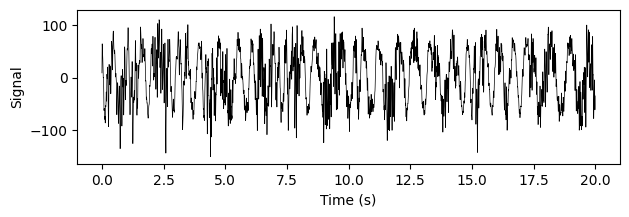

In [2]:
config = nfm.preprocessing.PreprocessConfig(
    notch_hz=50, band_hz=(1, 50), output_rate_hz=500,
    envelope_band_hz=(1, 80), envelope_lowpass_hz=3,
)
processed = nfm.preprocessing.process(
    recording.signal, sampling_rate_hz=recording.sampling_rate_hz, config=config,
)
x = processed.signal
plt.figure(figsize=(7, 2))
plt.plot(np.arange(len(x)) / processed.sampling_rate_hz, x, color="black", lw=.5)
plt.xlabel("Time (s)")
plt.ylabel("Signal")
plt.show()


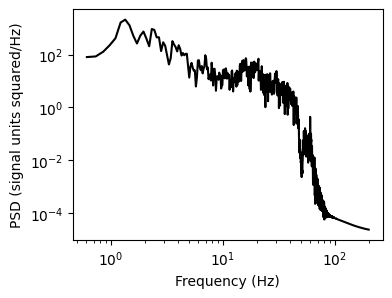

In [3]:
n_fft = min(4096, len(x))
psd = nfm.spectral.welch(x, sampling_rate_hz=500, n_fft=n_fft,
                         overlap_samples=n_fft // 2, frequency_range_hz=(.5, 200))
plt.figure(figsize=(4, 3))
plt.loglog(psd.frequencies_hz, psd.density, color="black")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (signal units squared/Hz)")
plt.show()


## Prediction

Fit the AR model on the earlier part of the recording and evaluate on the later part. One-step predictions use observed lag history; hybrid forecasts periodically refresh that history rather than running freely for the whole test segment.


PredictionMetrics(mse=23.665544196997157, mae=2.857319870249216, correlation=0.9952719188388804)


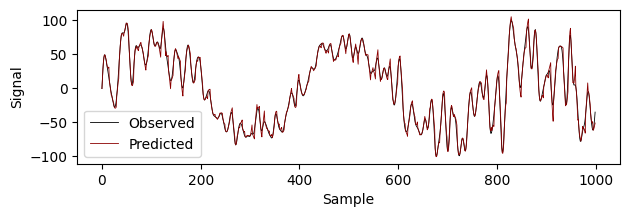

In [4]:
order = 4
n_train = int(0.9 * (len(x) - order))
fit = nfm.models.AR(order=order).fit(x[:n_train + order])
observed = x[n_train + order:]
prediction = fit.forecast(x, start_sample=n_train + order,
                          n_samples=len(observed), refresh_samples=5)
metrics = nfm.models.prediction_metrics(observed, prediction)
print(metrics)
plt.figure(figsize=(7, 2))
plt.plot(observed, color="black", label="Observed", lw=.6)
plt.plot(prediction, color="darkred", label="Predicted", lw=.6)
plt.xlabel("Sample")
plt.ylabel("Signal")
plt.legend()
plt.show()


## Delay Coordinates

Embed the observed and predicted signals and compare their trajectories. For this visualization, the prediction is rescaled to the observed segment's mean and standard deviation. Prediction errors above are computed before this display rescaling.


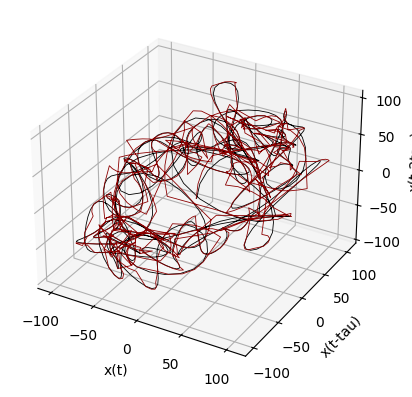

In [5]:
matched = prediction - prediction.mean()
matched = matched * (observed.std() / (matched.std() + 1e-12)) + observed.mean()
cloud = nfm.embedding.delay(observed.astype(np.float32), dimension=3, tau_samples=30)
predicted_cloud = nfm.embedding.delay(matched.astype(np.float32), dimension=3, tau_samples=30)
ax = nfm.plotting.embedding(cloud)
nfm.plotting.embedding(predicted_cloud, ax=ax, color="darkred")
plt.show()
